In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Python: /home/pnola130/.conda/envs/chart_retrieval/bin/python
PyTorch: 2.3.1+cu121
GPU available: True
GPU: NVIDIA A100-SXM4-80GB MIG 2g.20gb


In [2]:
from pathlib import Path

PROJECT_ROOT = Path("/home/pnola130/projects/chart_data_retrieval")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print(PROJECT_ROOT)

/home/pnola130/projects/chart_data_retrieval


In [3]:
from pathlib import Path

PROJECT_ROOT = Path("/home/pnola130/projects/chart_data_retrieval")

folders = [
    "configs",
    "src/data",
    "src/generation",
    "src/graph",
    "src/models",
    "src/training",
    "src/retrieval",
    "src/evaluation",
    "data/raw/chartqa",
    "data/raw/plotqa",
    "data/interim/canonical_tables",
    "data/interim/deplot_outputs",
    "data/interim/graphs",
    "data/processed",
    "generated_charts/positives",
    "generated_charts/hard_negatives",
    "artifacts/checkpoints",
    "artifacts/embeddings",
    "artifacts/indexes",
    "artifacts/logs",
    "artifacts/predictions",
    "reports",
]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Project created at:", PROJECT_ROOT)

Project created at: /home/pnola130/projects/chart_data_retrieval


In [4]:
!find /home/pnola130/projects/chart_data_retrieval -type d | sort

/home/pnola130/projects/chart_data_retrieval
/home/pnola130/projects/chart_data_retrieval/artifacts
/home/pnola130/projects/chart_data_retrieval/artifacts/checkpoints
/home/pnola130/projects/chart_data_retrieval/artifacts/embeddings
/home/pnola130/projects/chart_data_retrieval/artifacts/indexes
/home/pnola130/projects/chart_data_retrieval/artifacts/logs
/home/pnola130/projects/chart_data_retrieval/artifacts/predictions
/home/pnola130/projects/chart_data_retrieval/configs
/home/pnola130/projects/chart_data_retrieval/data
/home/pnola130/projects/chart_data_retrieval/data/interim
/home/pnola130/projects/chart_data_retrieval/data/interim/canonical_tables
/home/pnola130/projects/chart_data_retrieval/data/interim/deplot_outputs
/home/pnola130/projects/chart_data_retrieval/data/interim/graphs
/home/pnola130/projects/chart_data_retrieval/data/processed
/home/pnola130/projects/chart_data_retrieval/data/raw
/home/pnola130/projects/chart_data_retrieval/data/raw/chartqa
/home/pnola130/projects/cha

In [5]:
import torch
import transformers
import torch_geometric
import faiss

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

/etc/python/sitecustomize.py:117: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  mod = _original_import(name, globals, locals, fromlist, level)


PyTorch: 2.3.1+cu121
Transformers: 4.44.2
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB MIG 2g.20gb


In [34]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "projects" / "chart_data_retrieval"

CHARTQA_DIR = PROJECT_ROOT / "data" / "raw" / "chartqa"
zip_path = CHARTQA_DIR / "ChartQA Dataset.zip"

print("ZIP path:", zip_path)
print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    print(
        "Size:",
        
        round(zip_path.stat().st_size / (1024**2), 2),
        "MB"
    )

ZIP path: /home/pnola130/projects/chart_data_retrieval/data/raw/chartqa/ChartQA Dataset.zip
ZIP exists: True
Size: 834.82 MB


In [35]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as file:
    print("Validating ZIP...")
    bad_file = file.testzip()

    assert bad_file is None, f"Corrupted file: {bad_file}"

    print("Extracting...")
    file.extractall(CHARTQA_DIR)

DATASET_ROOT = CHARTQA_DIR / "ChartQA Dataset"

print("Dataset exists:", DATASET_ROOT.exists())
print("Dataset location:", DATASET_ROOT)

Validating ZIP...
Extracting...
Dataset exists: True
Dataset location: /home/pnola130/projects/chart_data_retrieval/data/raw/chartqa/ChartQA Dataset


In [36]:
for split in ["train", "val", "test"]:
    split_dir = DATASET_ROOT / split

    images = list((split_dir / "png").glob("*.png"))
    tables = list((split_dir / "tables").glob("*.csv"))
    annotations = list((split_dir / "annotations").glob("*.json"))
    question_files = list(split_dir.glob(f"{split}_*.json"))

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Tables:", len(tables))
    print("Annotations:", len(annotations))
    print("Question files:", [file.name for file in question_files])


--- TRAIN ---
Images: 18317
Tables: 18317
Annotations: 18317
Question files: ['train_human.json', 'train_augmented.json']

--- VAL ---
Images: 1056
Tables: 1056
Annotations: 1056
Question files: ['val_human.json', 'val_augmented.json']

--- TEST ---
Images: 1509
Tables: 1509
Annotations: 1509
Question files: ['test_human.json', 'test_augmented.json']


Inspect one table

In [37]:
import pandas as pd

sample_table_path = next(
    (DATASET_ROOT / "train" / "tables").glob("*.csv")
)

sample_table = pd.read_csv(sample_table_path)

print("Table file:", sample_table_path.name)
display(sample_table)

Table file: two_col_5636.csv


,Characteristic,Capacity in million dwt
0,2020,275
1,2019,266
2,2018,253
3,2017,246
4,2016,244
5,2015,228
6,2010,169
7,2005,98
8,2000,64
9,1995,44


Find its corresponding chart and annotation

In [38]:
sample_name = sample_table_path.stem

sample_image_path = (
    DATASET_ROOT / "train" / "png" / f"{sample_name}.png"
)

sample_annotation_path = (
    DATASET_ROOT / "train" / "annotations" / f"{sample_name}.json"
)

print("Sample ID:", sample_name)
print("Image exists:", sample_image_path.exists())
print("Annotation exists:", sample_annotation_path.exists())
print("Image path:", sample_image_path)

Sample ID: two_col_5636
Image exists: True
Annotation exists: True
Image path: /home/pnola130/projects/chart_data_retrieval/data/raw/chartqa/ChartQA Dataset/train/png/two_col_5636.png


Display the chart

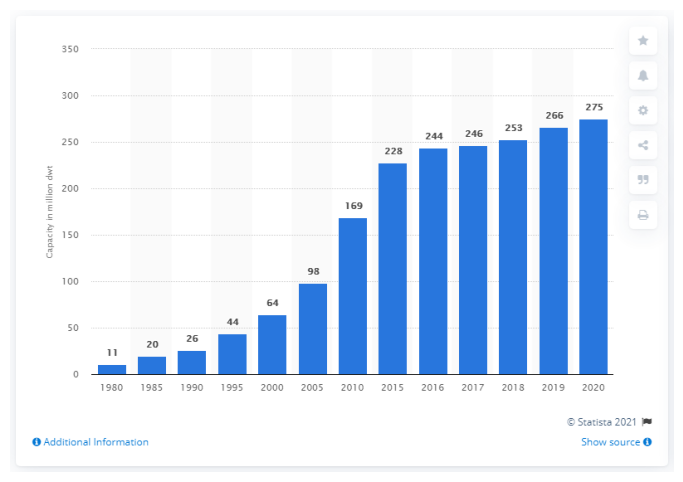

In [39]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(sample_image_path)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

nspect the corresponding annotation

In [40]:
import json

with open(sample_annotation_path, "r") as file:
    annotation = json.load(file)

print("Annotation keys:", annotation.keys())
print("Chart type:", annotation.get("type"))
print("Number of data series:", len(annotation.get("models", [])))

Annotation keys: dict_keys(['general_figure_info', 'models', 'type'])
Chart type: v_bar
Number of data series: 1


In [41]:
import json
from pathlib import Path

DATASET_ROOT = Path(
    "/home/pnola130/projects/chart_data_retrieval/data/raw/chartqa/ChartQA Dataset"
)

sample_id = "two_col_43237"

question_files = [
    DATASET_ROOT / "train" / "train_human.json",
    DATASET_ROOT / "train" / "train_augmented.json"
]

for question_file in question_files:
    with open(question_file, "r", encoding="utf-8") as file:
        records = json.load(file)

    print("\nFILE:", question_file.name)
    print("Total questions:", len(records))
    print("Available fields:", records[0].keys())
    print("First record:")
    print(json.dumps(records[0], indent=2))

    matching_questions = []

    for record in records:
        image_name = str(
            record.get(
                "imgname",
                record.get(
                    "image",
                    record.get("image_name", "")
                )
            )
        )

        if Path(image_name).stem == sample_id:
            matching_questions.append(record)

    print(f"\nQuestions for {sample_id}: {len(matching_questions)}")

    for question in matching_questions[:5]:
        print(json.dumps(question, indent=2))


FILE: train_human.json
Total questions: 7398
Available fields: dict_keys(['imgname', 'query', 'label'])
First record:
{
  "imgname": "10095.png",
  "query": "Is the value of Favorable 38 in 2015?",
  "label": "Yes"
}

Questions for two_col_43237: 0

FILE: train_augmented.json
Total questions: 20901
Available fields: dict_keys(['imgname', 'query', 'label'])
First record:
{
  "imgname": "two_col_103562.png",
  "query": "As of 2021, how many championship titles had Ferrari won?",
  "label": "16"
}

Questions for two_col_43237: 2
{
  "imgname": "two_col_43237.png",
  "query": "What is the estimated number of smartphone users in Israel in 2025?",
  "label": "7.64"
}
{
  "imgname": "two_col_43237.png",
  "query": "In 2025, what is the estimated number of mobile internet users in Israel?",
  "label": "7.64"
}


In [42]:
!pip install -q pandas pyarrow tqdm


In [43]:
SRC_DATA = PROJECT_ROOT / "src" / "data"

SRC_DATA.mkdir(parents=True, exist_ok=True)

(PROJECT_ROOT / "src" / "__init__.py").touch()
(SRC_DATA / "__init__.py").touch()

print("Source folder:", SRC_DATA)

Source folder: /home/pnola130/projects/chart_data_retrieval/src/data


In [44]:
%%writefile /home/pnola130/projects/chart_data_retrieval/src/data/chartqa_loader.py

import hashlib
import json
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm


def read_table(table_path):
    df = pd.read_csv(table_path, keep_default_na=False)

    # Convert Pandas/NumPy values into JSON-safe Python values
    table_object = json.loads(
        df.to_json(
            orient="split",
            force_ascii=False
        )
    )

    columns = [str(column) for column in table_object["columns"]]
    rows = table_object["data"]

    return columns, rows


def linearize_table(columns, rows):
    header = " | ".join(columns)

    row_texts = [
        " | ".join(
            "" if value is None else str(value)
            for value in row
        )
        for row in rows
    ]

    return " ; ".join([header] + row_texts)


def create_table_hash(columns, rows):
    content = json.dumps(
        {
            "columns": columns,
            "rows": rows
        },
        ensure_ascii=False,
        sort_keys=True
    )

    return hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()


def extract_title(annotation):
    title = (
        annotation
        .get("general_figure_info", {})
        .get("title", "")
    )

    if isinstance(title, str):
        return title

    if isinstance(title, dict):
        return str(title.get("text", ""))

    return ""


def build_chartqa(
    dataset_root,
    output_directory,
    limit_per_split=None
):
    dataset_root = Path(dataset_root)
    output_directory = Path(output_directory)
    output_directory.mkdir(parents=True, exist_ok=True)

    table_records = []
    chart_records = []
    query_records = []
    statistics = {}

    for split in ["train", "val", "test"]:
        split_directory = dataset_root / split

        images = {
            path.stem: path
            for path in (split_directory / "png").glob("*.png")
        }

        tables = {
            path.stem: path
            for path in (split_directory / "tables").glob("*.csv")
        }

        annotations = {
            path.stem: path
            for path in (
                split_directory / "annotations"
            ).glob("*.json")
        }

        # Only keep IDs that have image, table and annotation
        sample_ids = sorted(
            set(images)
            & set(tables)
            & set(annotations)
        )

        if limit_per_split is not None:
            sample_ids = sample_ids[:limit_per_split]

        selected_ids = set(sample_ids)

        print(
            f"\nProcessing {split}: "
            f"{len(sample_ids)} charts"
        )

        for sample_id in tqdm(sample_ids):
            with open(
                annotations[sample_id],
                "r",
                encoding="utf-8"
            ) as file:
                annotation = json.load(file)

            columns, rows = read_table(
                tables[sample_id]
            )

            data_id = f"chartqa_{split}_{sample_id}"
            chart_id = f"{data_id}_original"

            table_records.append({
                "data_id": data_id,
                "source_id": sample_id,
                "dataset": "chartqa",
                "split": split,
                "title": extract_title(annotation),
                "columns_json": json.dumps(
                    columns,
                    ensure_ascii=False
                ),
                "rows_json": json.dumps(
                    rows,
                    ensure_ascii=False
                ),
                "table_text": linearize_table(
                    columns,
                    rows
                ),
                "table_hash": create_table_hash(
                    columns,
                    rows
                ),
                "num_rows": len(rows),
                "num_columns": len(columns),
                "table_path": str(tables[sample_id])
            })

            chart_records.append({
                "chart_id": chart_id,
                "data_id": data_id,
                "source_id": sample_id,
                "dataset": "chartqa",
                "split": split,
                "image_path": str(images[sample_id]),
                "annotation_path": str(
                    annotations[sample_id]
                ),
                "chart_type": annotation.get(
                    "type",
                    "unknown"
                ),
                "num_series": len(
                    annotation.get("models", [])
                ),
                "style_id": "original",
                "variant_type": "original",
                "is_original": True
            })

        split_query_count = 0

        for question_source in ["human", "augmented"]:
            question_path = (
                split_directory
                / f"{split}_{question_source}.json"
            )

            with open(
                question_path,
                "r",
                encoding="utf-8"
            ) as file:
                questions = json.load(file)

            for index, question in enumerate(questions):
                sample_id = Path(
                    question["imgname"]
                ).stem

                # During smoke test, only retain selected charts
                if sample_id not in selected_ids:
                    continue

                data_id = f"chartqa_{split}_{sample_id}"
                chart_id = f"{data_id}_original"

                query_records.append({
                    "query_id": (
                        f"chartqa_{split}_"
                        f"{question_source}_{index}"
                    ),
                    "data_id": data_id,
                    "chart_id": chart_id,
                    "source_id": sample_id,
                    "dataset": "chartqa",
                    "split": split,
                    "question_source": question_source,
                    "question": str(question["query"]),
                    "answer": str(question["label"]),
                    "query_type": "unclassified"
                })

                split_query_count += 1

        statistics[split] = {
            "charts": len(sample_ids),
            "tables": len(sample_ids),
            "queries": split_query_count
        }

    tables_df = pd.DataFrame(table_records)
    charts_df = pd.DataFrame(chart_records)
    queries_df = pd.DataFrame(query_records)

    tables_df.to_parquet(
        output_directory / "tables.parquet",
        index=False
    )

    charts_df.to_parquet(
        output_directory / "charts.parquet",
        index=False
    )

    queries_df.to_parquet(
        output_directory / "queries.parquet",
        index=False
    )

    with open(
        output_directory / "dataset_statistics.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(statistics, file, indent=2)

    return tables_df, charts_df, queries_df, statistics

Writing /home/pnola130/projects/chart_data_retrieval/src/data/chartqa_loader.py


In [45]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data.chartqa_loader import build_chartqa

SMOKE_OUTPUT = (
    PROJECT_ROOT
    / "data"
    / "processed_smoke"
)

tables_df, charts_df, queries_df, statistics = build_chartqa(
    dataset_root=DATASET_ROOT,
    output_directory=SMOKE_OUTPUT,
    limit_per_split=100
)


Processing train: 100 charts


100%|██████████| 100/100 [00:00<00:00, 697.22it/s]



Processing val: 100 charts


100%|██████████| 100/100 [00:00<00:00, 727.88it/s]



Processing test: 100 charts


100%|██████████| 100/100 [00:00<00:00, 721.18it/s]


In [46]:
import json

print(json.dumps(statistics, indent=2))

print("\nTables:", tables_df.shape)
print("Charts:", charts_df.shape)
print("Queries:", queries_df.shape)

{
  "train": {
    "charts": 100,
    "tables": 100,
    "queries": 200
  },
  "val": {
    "charts": 100,
    "tables": 100,
    "queries": 200
  },
  "test": {
    "charts": 100,
    "tables": 100,
    "queries": 200
  }
}

Tables: (300, 12)
Charts: (300, 12)
Queries: (600, 10)


In [47]:
display(
    tables_df[
        [
            "data_id",
            "title",
            "num_rows",
            "num_columns",
            "table_text"
        ]
    ].head()
)

,data_id,title,num_rows,num_columns,table_text
0,chartqa_train_00006834003065,Projected share of the population in extreme p...,6,2,Country | Projected share of the population in...
1,chartqa_train_00035547003867,"Sex ratio at birth by birth order, China, 2000",3,2,"Country | Sex ratio at birth by birth order, C..."
2,chartqa_train_00035547003876,"Sex ratio at birth by birth order, South Korea...",4,10,Entity | 1986 | 1988 | 1990 | 1992 | 1994 | 19...
3,chartqa_train_00097754005965,Discriminatory attitudes towards people living...,5,2,Country | Discriminatory attitudes towards peo...
4,chartqa_train_00108924005661,"Death rates from substance use disorders, 1990...",5,9,Entity | 1990 | 1991 | 1992 | 1993 | 1994 | 19...


In [48]:
joined_sample = queries_df.merge(
    charts_df[
        [
            "chart_id",
            "data_id",
            "image_path",
            "chart_type"
        ]
    ],
    on=["chart_id", "data_id"],
    how="left"
).merge(
    tables_df[
        [
            "data_id",
            "table_text"
        ]
    ],
    on="data_id",
    how="left"
)

display(
    joined_sample[
        [
            "question",
            "answer",
            "chart_type",
            "image_path",
            "table_text"
        ]
    ].head()
)

,question,answer,chart_type,image_path,table_text
0,Is the value of Favorable 38 in 2015?,Yes,line,/home/pnola130/projects/chart_data_retrieval/d...,Year | Favorable | Unfavorable ; 2005 | 0 | 35...
1,How many values are below 40 in Unfavorable gr...,6,line,/home/pnola130/projects/chart_data_retrieval/d...,Year | Favorable | Unfavorable ; 2005 | 0 | 35...
2,Which country has longest bar?,Nigeria,h_bar,/home/pnola130/projects/chart_data_retrieval/d...,Country | Projected share of the population in...
3,Does the difference of largest two bar is exac...,No,h_bar,/home/pnola130/projects/chart_data_retrieval/d...,Country | Projected share of the population in...
4,How many bars are there in the graph?,3,h_bar,/home/pnola130/projects/chart_data_retrieval/d...,"Country | Sex ratio at birth by birth order, C..."


In [49]:
FULL_OUTPUT = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

tables_df, charts_df, queries_df, statistics = build_chartqa(
    dataset_root=DATASET_ROOT,
    output_directory=FULL_OUTPUT,
    limit_per_split=None
)

print(json.dumps(statistics, indent=2))


Processing train: 18317 charts


100%|██████████| 18317/18317 [00:25<00:00, 705.56it/s]



Processing val: 1056 charts


100%|██████████| 1056/1056 [00:01<00:00, 745.14it/s]



Processing test: 1509 charts


100%|██████████| 1509/1509 [00:02<00:00, 750.06it/s]


{
  "train": {
    "charts": 18317,
    "tables": 18317,
    "queries": 28299
  },
  "val": {
    "charts": 1056,
    "tables": 1056,
    "queries": 1920
  },
  "test": {
    "charts": 1509,
    "tables": 1509,
    "queries": 2500
  }
}


In [66]:
print("Tables:", len(tables_df))
print("Charts:", len(charts_df))
print("Queries:", len(queries_df))

assert len(tables_df) == 20882
assert len(charts_df) == 20882

print("Full ChartQA processing completed successfully")

Tables: 20882
Charts: 20882
Queries: 32719
Full ChartQA processing completed successfully


In [67]:
assert tables_df["data_id"].is_unique
assert charts_df["chart_id"].is_unique
assert queries_df["query_id"].is_unique

print("All IDs are unique")

All IDs are unique


In [68]:
validation_df = (
    queries_df
    .merge(
        charts_df[["chart_id", "data_id"]],
        on=["chart_id", "data_id"],
        how="left",
        indicator="chart_match"
    )
    .merge(
        tables_df[["data_id", "table_text"]],
        on="data_id",
        how="left",
        indicator="table_match"
    )
)

print(
    validation_df["chart_match"].value_counts()
)

print(
    validation_df["table_match"].value_counts()
)

assert (
    validation_df["chart_match"] == "both"
).all()

assert (
    validation_df["table_match"] == "both"
).all()

print("Every query has a matching chart and table")

chart_match
both          32719
left_only         0
right_only        0
Name: count, dtype: int64
table_match
both          32719
left_only         0
right_only        0
Name: count, dtype: int64
Every query has a matching chart and table


In [69]:
for path in FULL_OUTPUT.iterdir():
    print(path.name, "-", round(path.stat().st_size / 1024**2, 2), "MB")

queries.parquet - 2.02 MB
dataset_statistics.json - 0.0 MB
charts.parquet - 0.87 MB
tables.parquet - 8.29 MB


Select tables


In [70]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/home/pnola130/projects/chart_data_retrieval")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

tables_df = pd.read_parquet(
    PROCESSED_DIR / "tables.parquet"
)

print("Total tables:", len(tables_df))

Total tables: 20882


In [71]:
def convert_to_number(value):
    if isinstance(value, (int, float)):
        return float(value)

    text = str(value).strip()

    # Handle negative numbers such as (20.5)
    negative = text.startswith("(") and text.endswith(")")

    text = text.replace(",", "")
    text = text.replace("$", "")
    text = text.replace("%", "")
    text = re.sub(r"[*†‡]+$", "", text).strip()

    if negative:
        text = text[1:-1]

    try:
        number = float(text)
        return -number if negative else number
    except ValueError:
        return None

In [72]:
def inspect_table(row):
    columns = json.loads(row["columns_json"])
    rows = json.loads(row["rows_json"])

    if len(columns) != 2:
        return None

    if not 3 <= len(rows) <= 15:
        return None

    categories = [
        str(table_row[0]).strip()
        for table_row in rows
    ]

    values = [
        convert_to_number(table_row[1])
        for table_row in rows
    ]

    if any(category == "" for category in categories):
        return None

    if len(set(categories)) != len(categories):
        return None

    if any(value is None for value in values):
        return None

    if len(set(values)) < 2:
        return None

    return {
        "category_column": str(columns[0]),
        "value_column": str(columns[1]),
        "categories_json": json.dumps(categories),
        "values_json": json.dumps(values)
    }

In [73]:
eligible_records = []

for _, row in tables_df.iterrows():
    result = inspect_table(row)

    if result is None:
        continue

    record = row.to_dict()
    record.update(result)
    eligible_records.append(record)

eligible_df = pd.DataFrame(eligible_records)

print("Eligible tables:", len(eligible_df))
print("\nEligible tables by split:")
print(eligible_df["split"].value_counts())

Eligible tables: 11509

Eligible tables by split:
split
train    10161
test       812
val        536
Name: count, dtype: int64


In [74]:
display(
    eligible_df[
        [
            "data_id",
            "split",
            "title",
            "category_column",
            "value_column",
            "num_rows"
        ]
    ].head(10)
)

,data_id,split,title,category_column,value_column,num_rows
0,chartqa_train_00006834003065,train,Projected share of the population in extreme p...,Country,Projected share of the population in extreme p...,6
1,chartqa_train_00035547003867,train,"Sex ratio at birth by birth order, China, 2000",Country,"Sex ratio at birth by birth order, China, 2000",3
2,chartqa_train_00097754005965,train,Discriminatory attitudes towards people living...,Country,Discriminatory attitudes towards people living...,5
3,chartqa_train_00268016000783,train,"Private health expenditure per person, 2004",Country,"Private health expenditure per person, 2004",3
4,chartqa_train_00784700010464,train,"Carbon footprint of travel per kilometer, 2018",Country,"Carbon footprint of travel per kilometer, 2018",12
5,chartqa_train_00916448003743,train,Total financial assistance and flows for agric...,Country,Total financial assistance and flows for agric...,4
6,chartqa_train_01200566001630,train,Protein-energy malnutrition death rates by age...,Country,Protein-energy malnutrition death rates by age...,7
7,chartqa_train_01503134001790,train,Armed forces personnel (% of total labor force...,Country,Armed forces personnel (% of total labor force...,3
8,chartqa_train_01606743005377,train,"Meat supply per person, 1999",Country,"Meat supply per person, 1999",3
9,chartqa_train_01749121006280,train,Share of population who have ever been homeles...,Country,Share of population who have ever been homeles...,5


Train: 500 base tables
Validation: 100 base tables
Test: 100 base tables

In [75]:
pilot_sizes = {
    "train": 500,
    "val": 100,
    "test": 100
}

pilot_parts = []

for split, requested_size in pilot_sizes.items():
    split_tables = eligible_df[
        eligible_df["split"] == split
    ]

    actual_size = min(
        requested_size,
        len(split_tables)
    )

    selected = split_tables.sample(
        n=actual_size,
        random_state=42
    )

    pilot_parts.append(selected)

pilot_df = pd.concat(
    pilot_parts,
    ignore_index=True
)

print("Pilot tables:", len(pilot_df))
print(pilot_df["split"].value_counts())

Pilot tables: 700
split
train    500
val      100
test     100
Name: count, dtype: int64


In [60]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/home/pnola130/projects/chart_data_retrieval"
)

BENCHMARK_DIR = (
    PROJECT_ROOT
    / "data"
    / "benchmark"
)

PILOT_PATH = (
    BENCHMARK_DIR
    / "pilot_tables.parquet"
)

print("Project exists:", PROJECT_ROOT.exists())
print("Pilot path:", PILOT_PATH)
print("Pilot exists:", PILOT_PATH.exists())

Project exists: True
Pilot path: /home/pnola130/projects/chart_data_retrieval/data/benchmark/pilot_tables.parquet
Pilot exists: False


In [80]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
BENCHMARK_DIR = PROJECT_ROOT / "data" / "benchmark"

files_to_check = [
    PROCESSED_DIR / "tables.parquet",
    PROCESSED_DIR / "charts.parquet",
    PROCESSED_DIR / "queries.parquet",
    BENCHMARK_DIR / "pilot_tables.parquet",
]

for path in files_to_check:
    print(path.name, ":", path.exists())

tables.parquet : True
charts.parquet : True
queries.parquet : True
pilot_tables.parquet : False


In [81]:
!pip install -q pandas pyarrow numpy matplotlib pillow tqdm

In [82]:
%%writefile /home/pnola130/projects/chart_data_retrieval/src/generation/benchmark_generator.py

import hashlib
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm


def stable_seed(text, global_seed=42):
    value = hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()

    return int(value[:8], 16) + global_seed


def shuffle_values(values, data_id, global_seed=42):
    values = np.array(values, dtype=float)

    rng = np.random.default_rng(
        stable_seed(data_id, global_seed)
    )

    for _ in range(20):
        shuffled = rng.permutation(values)

        if not np.array_equal(shuffled, values):
            return shuffled.tolist()

    # Safe fallback
    shuffled = np.roll(values, 1)

    if np.array_equal(shuffled, values):
        shuffled = values[::-1]

    return shuffled.tolist()


def table_text(columns, rows):
    header = " | ".join(
        str(column) for column in columns
    )

    row_text = [
        " | ".join(str(value) for value in row)
        for row in rows
    ]

    return " ; ".join([header] + row_text)


def table_hash(columns, rows):
    content = json.dumps(
        {
            "columns": columns,
            "rows": rows
        },
        ensure_ascii=False,
        sort_keys=True
    )

    return hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()


def get_title(row):
    title = row.get("title", "")

    if pd.isna(title) or str(title).strip() == "":
        return (
            f"{row['value_column']} by "
            f"{row['category_column']}"
        )

    return str(title)


def render_vertical_blue(
    categories,
    values,
    title,
    category_label,
    value_label,
    output_path
):
    width = max(8, len(categories) * 0.6)

    fig, ax = plt.subplots(
        figsize=(width, 5),
        dpi=120
    )

    positions = np.arange(len(categories))

    ax.bar(
        positions,
        values,
        color="#4C78A8",
        edgecolor="#2F4B6C",
        linewidth=0.8
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        categories,
        rotation=40,
        ha="right"
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel(category_label)
    ax.set_ylabel(value_label)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.35
    )

    ax.axhline(0, color="black", linewidth=0.8)

    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    fig.tight_layout()
    fig.savefig(
        output_path,
        bbox_inches="tight"
    )
    plt.close(fig)


def render_horizontal_orange(
    categories,
    values,
    title,
    category_label,
    value_label,
    output_path
):
    height = max(5, len(categories) * 0.45)

    fig, ax = plt.subplots(
        figsize=(9, height),
        dpi=120
    )

    positions = np.arange(len(categories))

    ax.barh(
        positions,
        values,
        color="#F58518",
        edgecolor="#A65300",
        linewidth=0.8
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(categories)
    ax.invert_yaxis()

    ax.set_title(title, fontsize=13)
    ax.set_xlabel(value_label)
    ax.set_ylabel(category_label)

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.4
    )

    ax.axvline(0, color="black", linewidth=0.8)

    fig.patch.set_facecolor("#F4F4F4")
    ax.set_facecolor("#F4F4F4")

    fig.tight_layout()
    fig.savefig(
        output_path,
        bbox_inches="tight"
    )
    plt.close(fig)


def choose_subset(pilot_df, limit_per_split):
    if limit_per_split is None:
        return pilot_df.copy()

    parts = []

    for split in ["train", "val", "test"]:
        split_df = pilot_df[
            pilot_df["split"] == split
        ]

        parts.append(
            split_df.head(limit_per_split)
        )

    return pd.concat(
        parts,
        ignore_index=True
    )


def generate_benchmark(
    pilot_path,
    output_directory,
    image_directory,
    limit_per_split=None,
    global_seed=42
):
    pilot_df = pd.read_parquet(pilot_path)

    pilot_df = choose_subset(
        pilot_df,
        limit_per_split
    )

    output_directory = Path(output_directory)
    image_directory = Path(image_directory)

    output_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    image_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    chart_records = []
    table_records = []
    pair_records = []

    for _, row in tqdm(
        pilot_df.iterrows(),
        total=len(pilot_df),
        desc="Generating chart triplets"
    ):
        data_id = row["data_id"]
        split = row["split"]

        categories = json.loads(
            row["categories_json"]
        )

        values = [
            float(value)
            for value in json.loads(
                row["values_json"]
            )
        ]

        columns = [
            row["category_column"],
            row["value_column"]
        ]

        original_rows = [
            [category, value]
            for category, value in zip(
                categories,
                values
            )
        ]

        shuffled_values = shuffle_values(
            values,
            data_id,
            global_seed
        )

        shuffled_rows = [
            [category, value]
            for category, value in zip(
                categories,
                shuffled_values
            )
        ]

        negative_data_id = (
            f"{data_id}__shuffled"
        )

        anchor_chart_id = (
            f"{data_id}__vbar_blue"
        )

        positive_chart_id = (
            f"{data_id}__hbar_orange"
        )

        negative_chart_id = (
            f"{negative_data_id}__vbar_blue"
        )

        chart_folder = (
            image_directory
            / split
            / row["source_id"]
        )

        chart_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        anchor_path = (
            chart_folder
            / "anchor_vbar_blue.png"
        )

        positive_path = (
            chart_folder
            / "positive_hbar_orange.png"
        )

        negative_path = (
            chart_folder
            / "negative_vbar_blue.png"
        )

        title = get_title(row)

        render_vertical_blue(
            categories=categories,
            values=values,
            title=title,
            category_label=row["category_column"],
            value_label=row["value_column"],
            output_path=anchor_path
        )

        render_horizontal_orange(
            categories=categories,
            values=values,
            title=title,
            category_label=row["category_column"],
            value_label=row["value_column"],
            output_path=positive_path
        )

        # Exactly the same rendering style as the anchor
        render_vertical_blue(
            categories=categories,
            values=shuffled_values,
            title=title,
            category_label=row["category_column"],
            value_label=row["value_column"],
            output_path=negative_path
        )

        chart_records.extend([
            {
                "chart_id": anchor_chart_id,
                "data_id": data_id,
                "source_data_id": data_id,
                "split": split,
                "image_path": str(anchor_path),
                "chart_type": "v_bar",
                "style_id": "vbar_blue",
                "variant_type": "anchor",
                "is_hard_negative": False
            },
            {
                "chart_id": positive_chart_id,
                "data_id": data_id,
                "source_data_id": data_id,
                "split": split,
                "image_path": str(positive_path),
                "chart_type": "h_bar",
                "style_id": "hbar_orange",
                "variant_type": "positive",
                "is_hard_negative": False
            },
            {
                "chart_id": negative_chart_id,
                "data_id": negative_data_id,
                "source_data_id": data_id,
                "split": split,
                "image_path": str(negative_path),
                "chart_type": "v_bar",
                "style_id": "vbar_blue",
                "variant_type": "hard_negative",
                "is_hard_negative": True
            }
        ])

        table_records.extend([
            {
                "data_id": data_id,
                "source_data_id": data_id,
                "split": split,
                "columns_json": json.dumps(columns),
                "rows_json": json.dumps(original_rows),
                "table_text": table_text(
                    columns,
                    original_rows
                ),
                "table_hash": table_hash(
                    columns,
                    original_rows
                ),
                "variant_type": "original",
                "is_generated": False
            },
            {
                "data_id": negative_data_id,
                "source_data_id": data_id,
                "split": split,
                "columns_json": json.dumps(columns),
                "rows_json": json.dumps(shuffled_rows),
                "table_text": table_text(
                    columns,
                    shuffled_rows
                ),
                "table_hash": table_hash(
                    columns,
                    shuffled_rows
                ),
                "variant_type": "hard_negative",
                "is_generated": True
            }
        ])

        # Chart-to-chart triplet
        pair_records.append({
            "pair_id": f"{data_id}__chart_chart",
            "task": "chart_chart",
            "split": split,
            "anchor_id": anchor_chart_id,
            "positive_id": positive_chart_id,
            "negative_id": negative_chart_id,
            "anchor_modality": "chart",
            "positive_modality": "chart",
            "negative_modality": "chart",
            "source_data_id": data_id,
            "negative_type": "same_style_different_data"
        })

        # Anchor chart-to-table triplet
        pair_records.append({
            "pair_id": f"{data_id}__vbar_chart_table",
            "task": "chart_table",
            "split": split,
            "anchor_id": anchor_chart_id,
            "positive_id": data_id,
            "negative_id": negative_data_id,
            "anchor_modality": "chart",
            "positive_modality": "table",
            "negative_modality": "table",
            "source_data_id": data_id,
            "negative_type": "value_shuffled"
        })

        # Positive chart-to-table triplet
        pair_records.append({
            "pair_id": f"{data_id}__hbar_chart_table",
            "task": "chart_table",
            "split": split,
            "anchor_id": positive_chart_id,
            "positive_id": data_id,
            "negative_id": negative_data_id,
            "anchor_modality": "chart",
            "positive_modality": "table",
            "negative_modality": "table",
            "source_data_id": data_id,
            "negative_type": "value_shuffled"
        })

    charts_df = pd.DataFrame(chart_records)
    tables_df = pd.DataFrame(table_records)
    pairs_df = pd.DataFrame(pair_records)

    charts_df.to_parquet(
        output_directory / "generated_charts.parquet",
        index=False
    )

    tables_df.to_parquet(
        output_directory / "benchmark_tables.parquet",
        index=False
    )

    pairs_df.to_parquet(
        output_directory / "retrieval_pairs.parquet",
        index=False
    )

    return charts_df, tables_df, pairs_df

Overwriting /home/pnola130/projects/chart_data_retrieval/src/generation/benchmark_generator.py


In [93]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.generation.benchmark_generator import generate_benchmark

SMOKE_BENCHMARK_DIR = (
    PROJECT_ROOT
    / "data"
    / "benchmark_smoke"
)

SMOKE_IMAGE_DIR = (
    PROJECT_ROOT
    / "generated_charts"
    / "smoke"
)

generated_charts_df, benchmark_tables_df, pairs_df = (
    generate_benchmark(
        pilot_path=PILOT_PATH,
        output_directory=SMOKE_BENCHMARK_DIR,
        image_directory=SMOKE_IMAGE_DIR,
        limit_per_split=5,
        global_seed=42
    )
)

print("Generated charts:", len(generated_charts_df))
print("Benchmark tables:", len(benchmark_tables_df))
print("Retrieval pairs:", len(pairs_df))

Generating chart triplets: 100%|██████████| 15/15 [00:06<00:00,  2.36it/s]

Generated charts: 45
Benchmark tables: 30
Retrieval pairs: 45


In [94]:
print("Generated chart records:", len(generated_charts_df))

display(
    generated_charts_df[
        [
            "source_data_id",
            "variant_type",
            "image_path"
        ]
    ].head(6)
)

Generated chart records: 45


,source_data_id,variant_type,image_path
0,chartqa_train_two_col_20843,anchor,/home/pnola130/projects/chart_data_retrieval/g...
1,chartqa_train_two_col_20843,positive,/home/pnola130/projects/chart_data_retrieval/g...
2,chartqa_train_two_col_20843,hard_negative,/home/pnola130/projects/chart_data_retrieval/g...
3,chartqa_train_two_col_63119,anchor,/home/pnola130/projects/chart_data_retrieval/g...
4,chartqa_train_two_col_63119,positive,/home/pnola130/projects/chart_data_retrieval/g...
5,chartqa_train_two_col_63119,hard_negative,/home/pnola130/projects/chart_data_retrieval/g...


In [95]:
from pathlib import Path

for image_path in generated_charts_df["image_path"].head(6):
    path = Path(image_path)

    print(
        path.name,
        "| exists:", path.exists(),
        "| size:", path.stat().st_size if path.exists() else 0
    )

anchor_vbar_blue.png | exists: True | size: 43629
positive_hbar_orange.png | exists: True | size: 44681
negative_vbar_blue.png | exists: True | size: 43673
anchor_vbar_blue.png | exists: True | size: 48598
positive_hbar_orange.png | exists: True | size: 54149
negative_vbar_blue.png | exists: True | size: 48604


Sample: chartqa_train_two_col_20843

 ANCHOR - v_bar


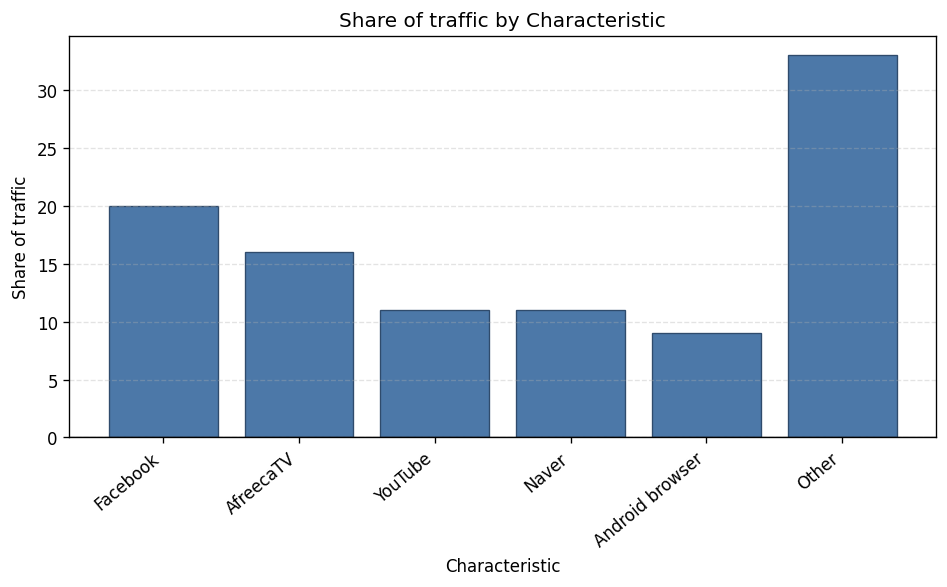


 POSITIVE - h_bar


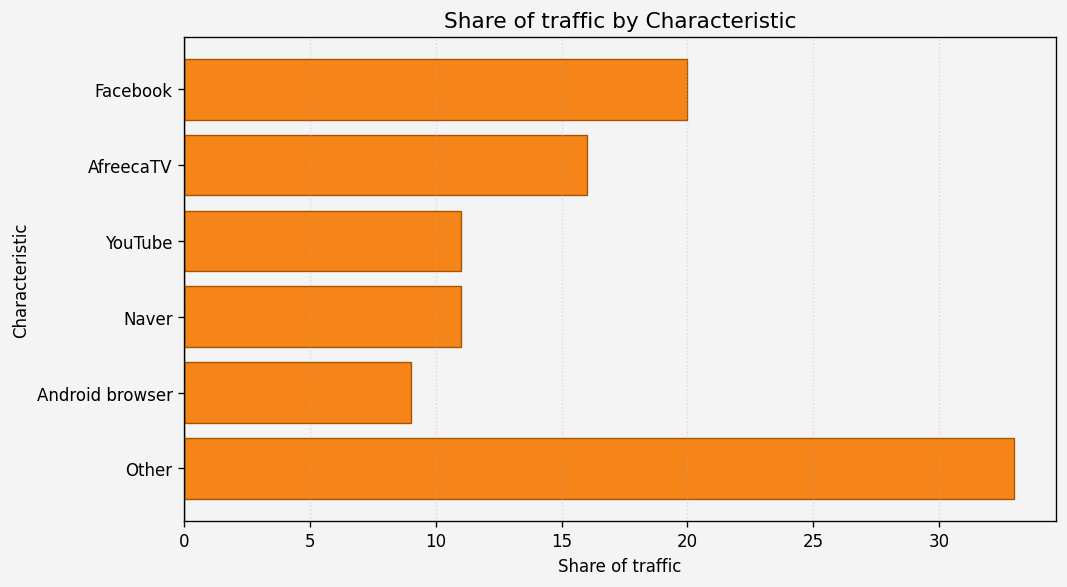


 HARD_NEGATIVE - v_bar


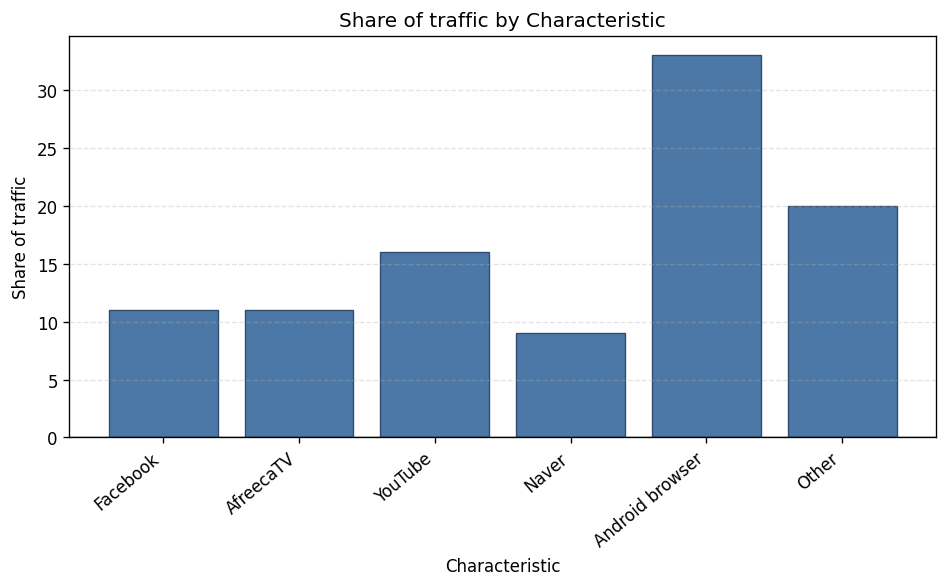

In [96]:
from IPython.display import display
from PIL import Image

sample_data_id = generated_charts_df.iloc[0]["source_data_id"]

sample_charts = generated_charts_df[
    generated_charts_df["source_data_id"] == sample_data_id
].copy()

display_order = {
    "anchor": 0,
    "positive": 1,
    "hard_negative": 2
}

sample_charts["display_order"] = (
    sample_charts["variant_type"].map(display_order)
)

sample_charts = sample_charts.sort_values("display_order")

print("Sample:", sample_data_id)

for _, chart in sample_charts.iterrows():
    print(
        "\n",
        chart["variant_type"].upper(),
        "-",
        chart["chart_type"]
    )

    image = Image.open(chart["image_path"])
    display(image)

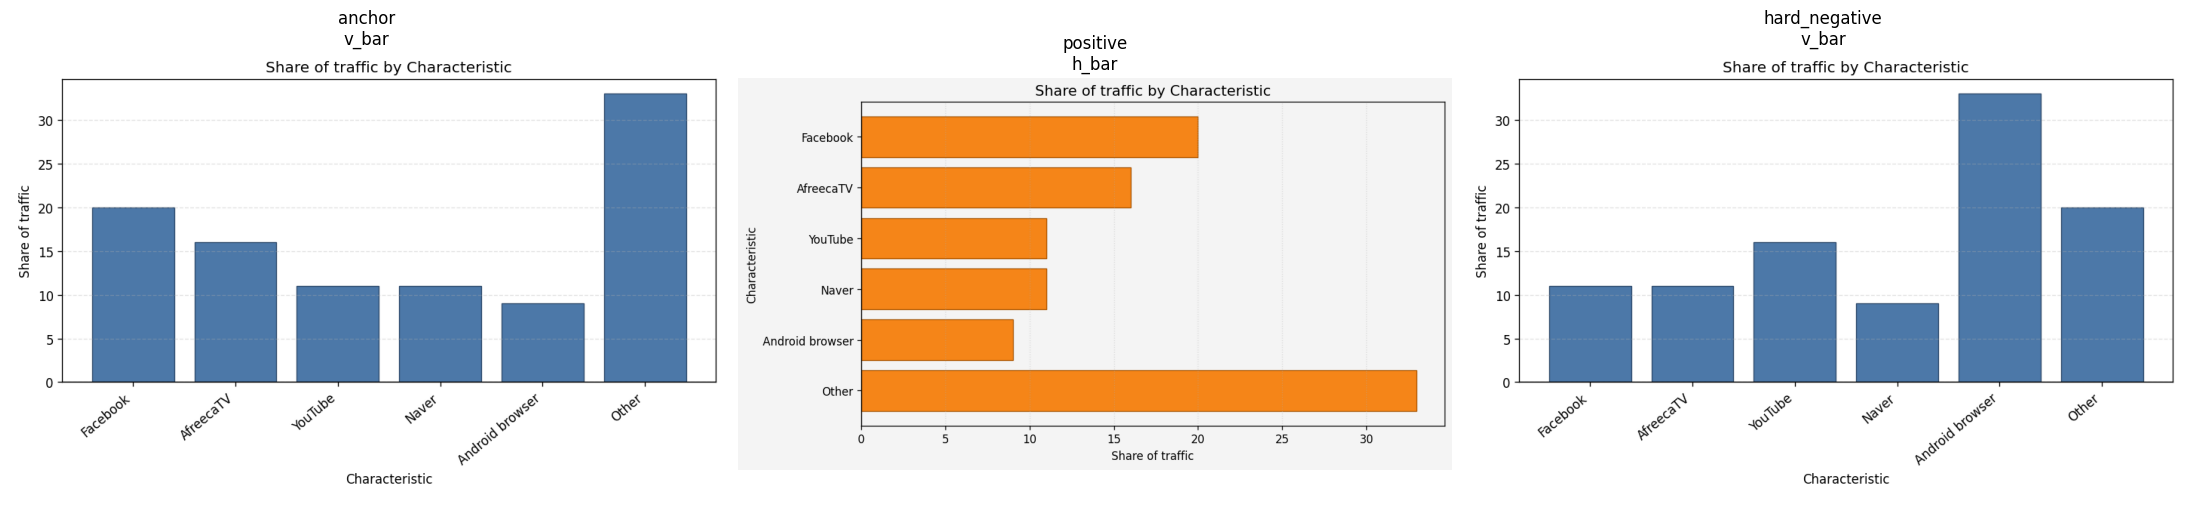

In [97]:
%matplotlib inline

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(
    1,
    3,
    figsize=(22, 6)
)

for axis, (_, chart) in zip(
    axes,
    sample_charts.iterrows()
):
    image = Image.open(chart["image_path"])

    axis.imshow(image)
    axis.set_title(
        f"{chart['variant_type']}\n"
        f"{chart['chart_type']}"
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

In [98]:
%%writefile /home/pnola130/projects/chart_data_retrieval/src/generation/add_chart_type_variants.py

import json
import re
from pathlib import Path

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from src.generation.benchmark_generator import (
    shuffle_values,
    get_title,
    choose_subset
)


def line_semantic_status(categories, category_label):
    label = str(category_label).lower()

    ordered_words = [
        "year", "date", "month", "time",
        "age", "quarter", "week"
    ]

    if any(word in label for word in ordered_words):
        return "ordered"

    cleaned = [
        re.sub(r"[^0-9.\-]", "", str(value))
        for value in categories
    ]

    try:
        [float(value) for value in cleaned]
        return "ordered"
    except ValueError:
        return "categorical_unverified"


def pie_is_valid(values):
    return (
        2 <= len(values) <= 8
        and all(value > 0 for value in values)
        and sum(values) > 0
    )


def render_line(
    categories,
    values,
    title,
    category_label,
    value_label,
    output_path
):
    width = max(8, len(categories) * 0.6)

    fig, ax = plt.subplots(
        figsize=(width, 5),
        dpi=120
    )

    positions = np.arange(len(categories))

    ax.plot(
        positions,
        values,
        color="#2CA02C",
        marker="o",
        markersize=7,
        linewidth=2.5
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        categories,
        rotation=40,
        ha="right"
    )

    ax.set_title(title)
    ax.set_xlabel(category_label)
    ax.set_ylabel(value_label)

    ax.grid(
        linestyle="--",
        alpha=0.35
    )

    ax.axhline(0, color="black", linewidth=0.8)

    fig.patch.set_facecolor("white")
    ax.set_facecolor("#F8FFF8")

    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.close(fig)


def render_pie(
    categories,
    values,
    title,
    output_path
):
    total = sum(values)

    def show_original_value(percent):
        value = percent * total / 100

        if abs(value) >= 100:
            return f"{value:.0f}"

        return f"{value:.2f}".rstrip("0").rstrip(".")

    colors = plt.cm.Set3(
        np.linspace(0, 1, len(categories))
    )

    fig, ax = plt.subplots(
        figsize=(8, 7),
        dpi=120
    )

    ax.pie(
        values,
        labels=categories,
        colors=colors,
        autopct=show_original_value,
        startangle=90,
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1
        }
    )

    ax.set_title(title)
    ax.axis("equal")

    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.close(fig)


def add_chart_type_variants(
    pilot_path,
    benchmark_directory,
    image_directory,
    limit_per_split=None,
    global_seed=42
):
    pilot_df = pd.read_parquet(pilot_path)

    pilot_df = choose_subset(
        pilot_df,
        limit_per_split
    )

    benchmark_directory = Path(benchmark_directory)
    image_directory = Path(image_directory)

    charts_path = (
        benchmark_directory
        / "generated_charts.parquet"
    )

    pairs_path = (
        benchmark_directory
        / "retrieval_pairs.parquet"
    )

    charts_df = pd.read_parquet(charts_path)
    pairs_df = pd.read_parquet(pairs_path)

    new_charts = []
    new_pairs = []

    existing_chart_ids = set(
        charts_df["chart_id"]
    )

    for _, row in tqdm(
        pilot_df.iterrows(),
        total=len(pilot_df),
        desc="Adding line and pie variants"
    ):
        data_id = row["data_id"]
        split = row["split"]

        anchor_id = f"{data_id}__vbar_blue"
        negative_data_id = f"{data_id}__shuffled"
        bar_negative_id = (
            f"{negative_data_id}__vbar_blue"
        )

        # Only extend tables already generated
        if anchor_id not in existing_chart_ids:
            continue

        categories = json.loads(
            row["categories_json"]
        )

        values = [
            float(value)
            for value in json.loads(
                row["values_json"]
            )
        ]

        shuffled_values = shuffle_values(
            values,
            data_id,
            global_seed
        )

        title = get_title(row)

        chart_folder = (
            image_directory
            / split
            / row["source_id"]
        )

        chart_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        # -------------------------
        # Line positive and negative
        # -------------------------

        line_positive_id = (
            f"{data_id}__line_green"
        )

        line_negative_id = (
            f"{negative_data_id}__line_green"
        )

        line_positive_path = (
            chart_folder
            / "positive_line_green.png"
        )

        line_negative_path = (
            chart_folder
            / "negative_line_green.png"
        )

        render_line(
            categories,
            values,
            title,
            row["category_column"],
            row["value_column"],
            line_positive_path
        )

        render_line(
            categories,
            shuffled_values,
            title,
            row["category_column"],
            row["value_column"],
            line_negative_path
        )

        line_status = line_semantic_status(
            categories,
            row["category_column"]
        )

        new_charts.extend([
            {
                "chart_id": line_positive_id,
                "data_id": data_id,
                "source_data_id": data_id,
                "split": split,
                "image_path": str(line_positive_path),
                "chart_type": "line",
                "style_id": "line_green",
                "variant_type": "hard_positive",
                "is_hard_negative": False,
                "semantic_status": line_status
            },
            {
                "chart_id": line_negative_id,
                "data_id": negative_data_id,
                "source_data_id": data_id,
                "split": split,
                "image_path": str(line_negative_path),
                "chart_type": "line",
                "style_id": "line_green",
                "variant_type": "hard_negative",
                "is_hard_negative": True,
                "semantic_status": line_status
            }
        ])

        # Bar anchor → line positive → bar negative
        new_pairs.append({
            "pair_id": f"{data_id}__bar_to_line",
            "task": "chart_chart",
            "split": split,
            "anchor_id": anchor_id,
            "positive_id": line_positive_id,
            "negative_id": bar_negative_id,
            "anchor_modality": "chart",
            "positive_modality": "chart",
            "negative_modality": "chart",
            "source_data_id": data_id,
            "negative_type": "same_style_different_data"
        })

        # Line anchor → bar positive → line negative
        new_pairs.append({
            "pair_id": f"{data_id}__line_to_bar",
            "task": "chart_chart",
            "split": split,
            "anchor_id": line_positive_id,
            "positive_id": anchor_id,
            "negative_id": line_negative_id,
            "anchor_modality": "chart",
            "positive_modality": "chart",
            "negative_modality": "chart",
            "source_data_id": data_id,
            "negative_type": "same_style_different_data"
        })

        # Line chart → matching table
        new_pairs.append({
            "pair_id": f"{data_id}__line_chart_table",
            "task": "chart_table",
            "split": split,
            "anchor_id": line_positive_id,
            "positive_id": data_id,
            "negative_id": negative_data_id,
            "anchor_modality": "chart",
            "positive_modality": "table",
            "negative_modality": "table",
            "source_data_id": data_id,
            "negative_type": "value_shuffled"
        })

        # -------------------------
        # Pie positive and negative
        # -------------------------

        if pie_is_valid(values):
            pie_positive_id = (
                f"{data_id}__pie_palette"
            )

            pie_negative_id = (
                f"{negative_data_id}__pie_palette"
            )

            pie_positive_path = (
                chart_folder
                / "positive_pie.png"
            )

            pie_negative_path = (
                chart_folder
                / "negative_pie.png"
            )

            render_pie(
                categories,
                values,
                title,
                pie_positive_path
            )

            render_pie(
                categories,
                shuffled_values,
                title,
                pie_negative_path
            )

            new_charts.extend([
                {
                    "chart_id": pie_positive_id,
                    "data_id": data_id,
                    "source_data_id": data_id,
                    "split": split,
                    "image_path": str(pie_positive_path),
                    "chart_type": "pie",
                    "style_id": "pie_palette",
                    "variant_type": "hard_positive",
                    "is_hard_negative": False,
                    "semantic_status": "composition_unverified"
                },
                {
                    "chart_id": pie_negative_id,
                    "data_id": negative_data_id,
                    "source_data_id": data_id,
                    "split": split,
                    "image_path": str(pie_negative_path),
                    "chart_type": "pie",
                    "style_id": "pie_palette",
                    "variant_type": "hard_negative",
                    "is_hard_negative": True,
                    "semantic_status": "composition_unverified"
                }
            ])

            new_pairs.extend([
                {
                    "pair_id": f"{data_id}__bar_to_pie",
                    "task": "chart_chart",
                    "split": split,
                    "anchor_id": anchor_id,
                    "positive_id": pie_positive_id,
                    "negative_id": bar_negative_id,
                    "anchor_modality": "chart",
                    "positive_modality": "chart",
                    "negative_modality": "chart",
                    "source_data_id": data_id,
                    "negative_type": "same_style_different_data"
                },
                {
                    "pair_id": f"{data_id}__pie_to_bar",
                    "task": "chart_chart",
                    "split": split,
                    "anchor_id": pie_positive_id,
                    "positive_id": anchor_id,
                    "negative_id": pie_negative_id,
                    "anchor_modality": "chart",
                    "positive_modality": "chart",
                    "negative_modality": "chart",
                    "source_data_id": data_id,
                    "negative_type": "same_style_different_data"
                },
                {
                    "pair_id": f"{data_id}__pie_chart_table",
                    "task": "chart_table",
                    "split": split,
                    "anchor_id": pie_positive_id,
                    "positive_id": data_id,
                    "negative_id": negative_data_id,
                    "anchor_modality": "chart",
                    "positive_modality": "table",
                    "negative_modality": "table",
                    "source_data_id": data_id,
                    "negative_type": "value_shuffled"
                }
            ])

    updated_charts = pd.concat(
        [
            charts_df,
            pd.DataFrame(new_charts)
        ],
        ignore_index=True
    ).drop_duplicates(
        subset=["chart_id"],
        keep="last"
    )

    updated_pairs = pd.concat(
        [
            pairs_df,
            pd.DataFrame(new_pairs)
        ],
        ignore_index=True
    ).drop_duplicates(
        subset=["pair_id"],
        keep="last"
    )

    updated_charts.to_parquet(
        charts_path,
        index=False
    )

    updated_pairs.to_parquet(
        pairs_path,
        index=False
    )

    return updated_charts, updated_pairs

Overwriting /home/pnola130/projects/chart_data_retrieval/src/generation/add_chart_type_variants.py


In [99]:
import json
import re
from pathlib import Path

import pandas as pd

# SOL project paths
PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
BENCHMARK_DIR = PROJECT_ROOT / "data" / "benchmark"

BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

TABLES_PATH = PROCESSED_DIR / "tables.parquet"
PILOT_PATH = BENCHMARK_DIR / "pilot_tables.parquet"

assert TABLES_PATH.exists(), (
    f"Processed tables not found: {TABLES_PATH}"
)

# Load all processed ChartQA tables
tables_df = pd.read_parquet(TABLES_PATH)

print("Total tables:", len(tables_df))


def convert_to_number(value):
    if isinstance(value, (int, float)):
        return float(value)

    text = str(value).strip()

    # Handle negatives such as (20.5)
    negative = (
        text.startswith("(")
        and text.endswith(")")
    )

    text = text.replace(",", "")
    text = text.replace("$", "")
    text = text.replace("%", "")
    text = re.sub(
        r"[*†‡]+$",
        "",
        text
    ).strip()

    if negative:
        text = text[1:-1]

    try:
        number = float(text)
        return -number if negative else number
    except ValueError:
        return None


def inspect_table(row):
    columns = json.loads(row["columns_json"])
    rows = json.loads(row["rows_json"])

    # Keep two-column tables only
    if len(columns) != 2:
        return None

    # Keep charts with 3–15 categories
    if not 3 <= len(rows) <= 15:
        return None

    categories = [
        str(table_row[0]).strip()
        for table_row in rows
    ]

    values = [
        convert_to_number(table_row[1])
        for table_row in rows
    ]

    # Remove empty or repeated categories
    if any(category == "" for category in categories):
        return None

    if len(set(categories)) != len(categories):
        return None

    # Require numeric values
    if any(value is None for value in values):
        return None

    # Require at least two distinct values
    if len(set(values)) < 2:
        return None

    return {
        "category_column": str(columns[0]),
        "value_column": str(columns[1]),
        "categories_json": json.dumps(categories),
        "values_json": json.dumps(values),
    }


# Find eligible tables
eligible_records = []

for _, row in tables_df.iterrows():
    result = inspect_table(row)

    if result is None:
        continue

    record = row.to_dict()
    record.update(result)
    eligible_records.append(record)

eligible_df = pd.DataFrame(eligible_records)

print("Eligible tables:", len(eligible_df))
print(eligible_df["split"].value_counts())


# Select 700 tables deterministically
pilot_sizes = {
    "train": 500,
    "val": 100,
    "test": 100,
}

pilot_parts = []

for split, requested_size in pilot_sizes.items():
    split_tables = eligible_df[
        eligible_df["split"] == split
    ]

    assert len(split_tables) >= requested_size, (
        f"Not enough eligible {split} tables: "
        f"{len(split_tables)}"
    )

    selected = split_tables.sample(
        n=requested_size,
        random_state=42,
    )

    pilot_parts.append(selected)

pilot_df = pd.concat(
    pilot_parts,
    ignore_index=True,
)

# This save operation was missing from the notebook
pilot_df.to_parquet(
    PILOT_PATH,
    index=False,
)

# Final validation
assert len(pilot_df) == 700
assert PILOT_PATH.exists()

print("\nPilot tables:", len(pilot_df))
print(pilot_df["split"].value_counts())
print("Saved to:", PILOT_PATH)
print("Pilot exists:", PILOT_PATH.exists())

Total tables: 20882
Eligible tables: 11509
split
train    10161
test       812
val        536
Name: count, dtype: int64

Pilot tables: 700
split
train    500
val      100
test     100
Name: count, dtype: int64
Saved to: /home/pnola130/projects/chart_data_retrieval/data/benchmark/pilot_tables.parquet
Pilot exists: True


In [100]:
required_files = [
    PROJECT_ROOT / "src" / "generation" / "benchmark_generator.py",
    PROJECT_ROOT / "src" / "generation" / "add_chart_type_variants.py",
    PILOT_PATH
]

for path in required_files:
    print(path.name, ":", path.exists())

assert all(path.exists() for path in required_files)

print("All required files are available")

benchmark_generator.py : True
add_chart_type_variants.py : True
pilot_tables.parquet : True
All required files are available


Overwriting /content/chart_data_retrieval/src/generation/add_chart_type_variants.py


In [101]:
from src.generation.add_chart_type_variants import (
    add_chart_type_variants
)

generated_charts_df, pairs_df = (
    add_chart_type_variants(
        pilot_path=PILOT_PATH,
        benchmark_directory=SMOKE_BENCHMARK_DIR,
        image_directory=SMOKE_IMAGE_DIR,
        limit_per_split=5,
        global_seed=42
    )
)

print(
    generated_charts_df["variant_type"].value_counts()
)

print(
    generated_charts_df["chart_type"].value_counts()
)

print("Total pairs:", len(pairs_df))

Adding line and pie variants: 100%|██████████| 15/15 [00:05<00:00,  2.86it/s]

variant_type
hard_negative    35
hard_positive    20
anchor           15
positive         15
Name: count, dtype: int64
chart_type
v_bar    30
line     30
h_bar    15
pie      10
Name: count, dtype: int64
Total pairs: 105



 positive | h_bar | data: chartqa_train_two_col_20843


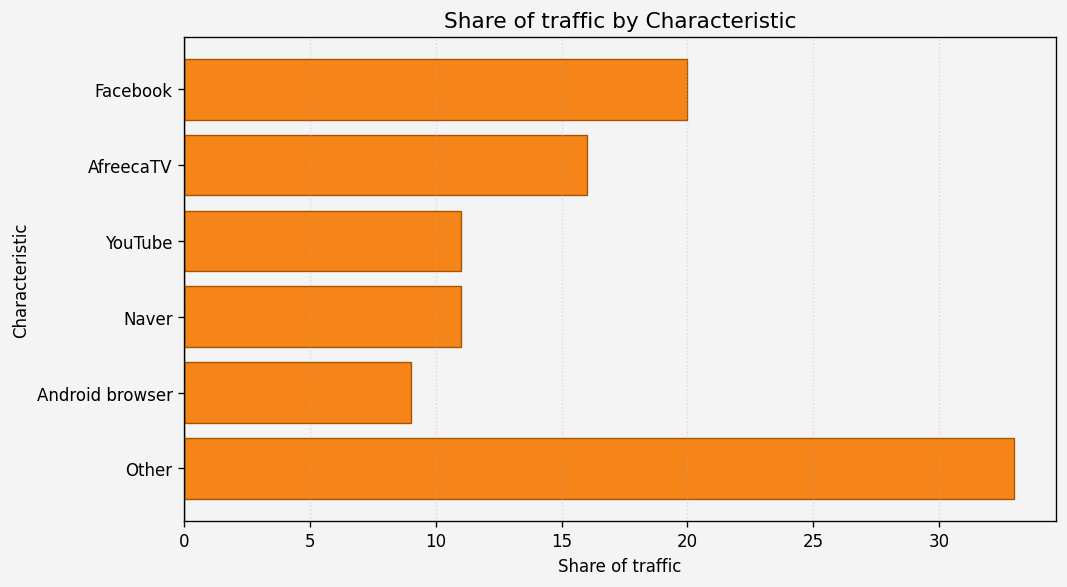


 hard_negative | line | data: chartqa_train_two_col_20843__shuffled


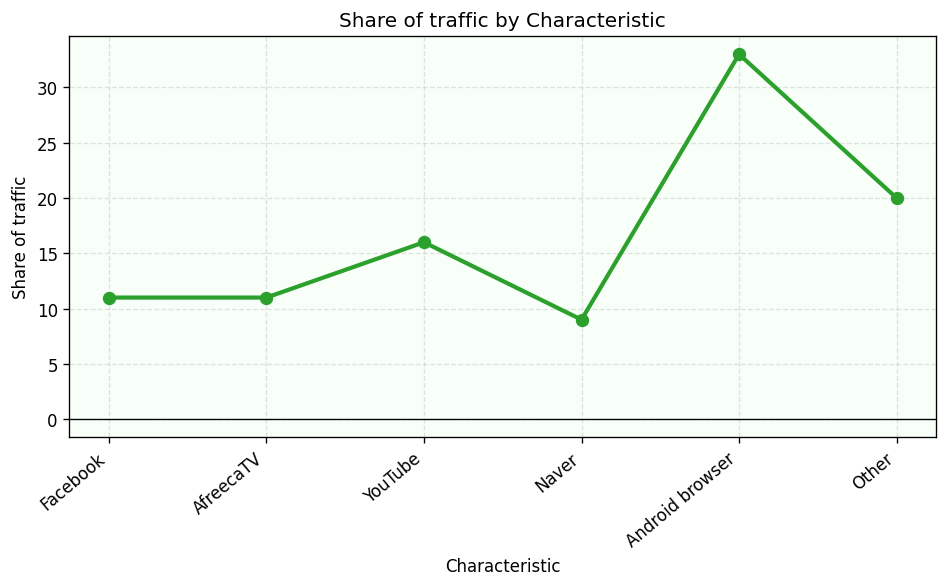


 hard_positive | line | data: chartqa_train_two_col_20843


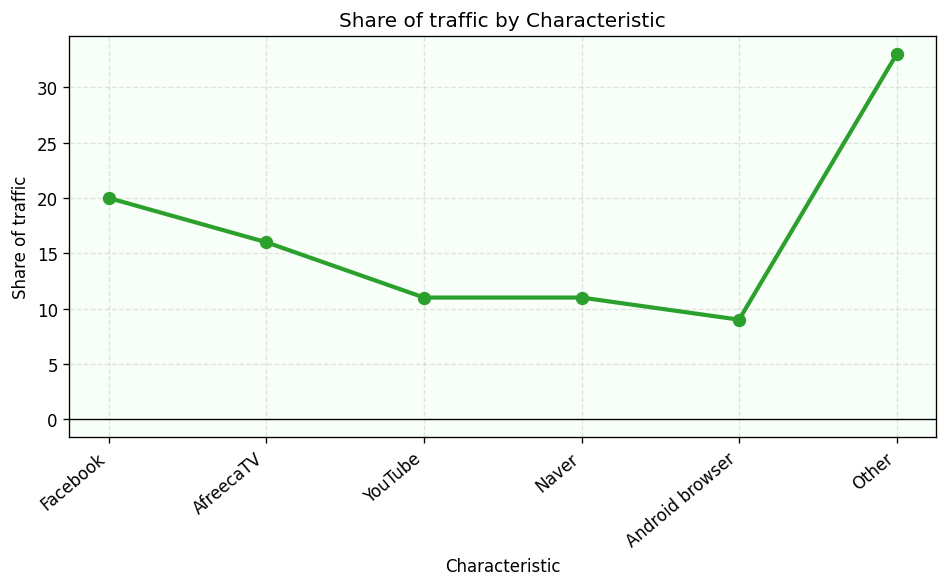


 hard_negative | pie | data: chartqa_train_two_col_20843__shuffled


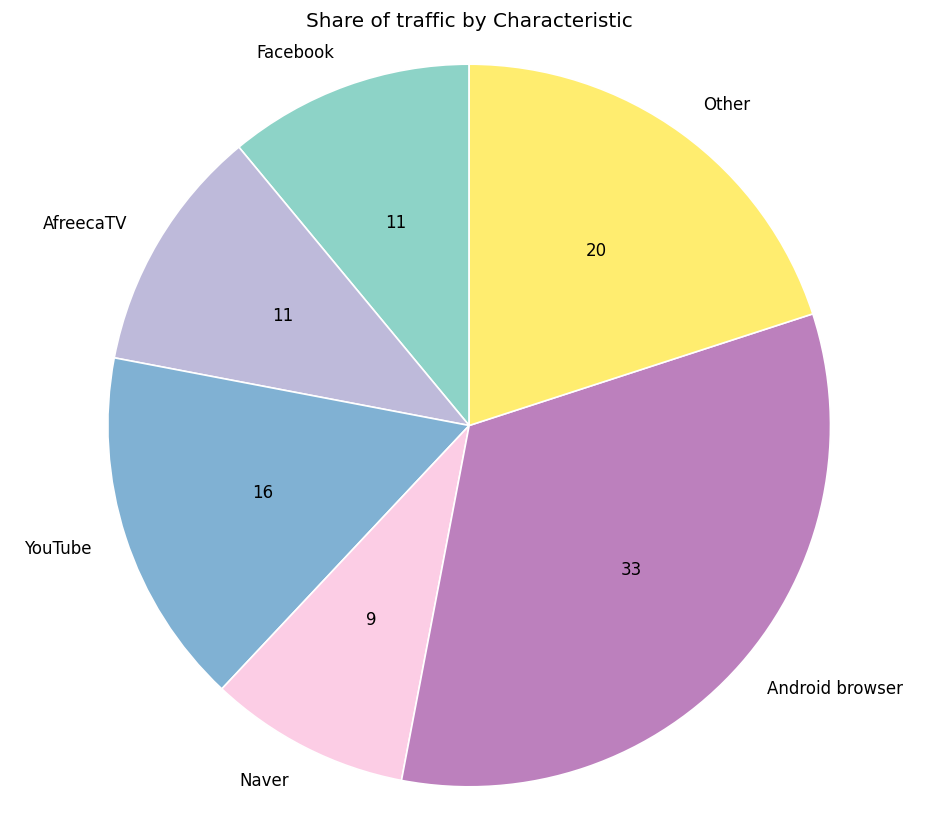


 hard_positive | pie | data: chartqa_train_two_col_20843


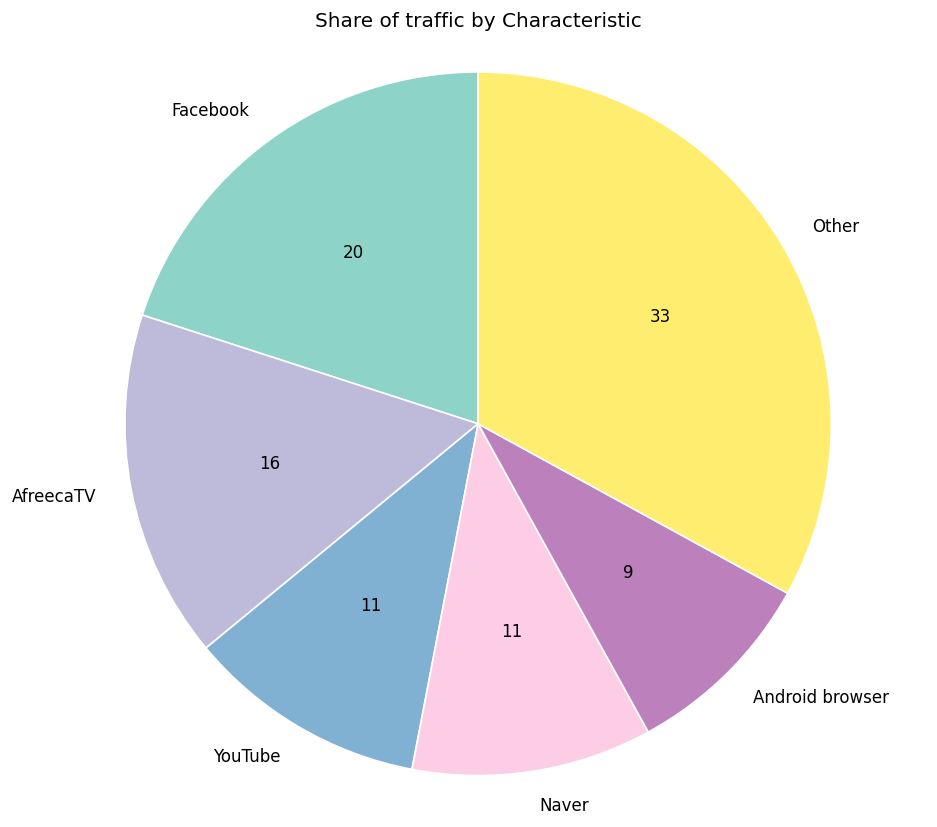


 anchor | v_bar | data: chartqa_train_two_col_20843


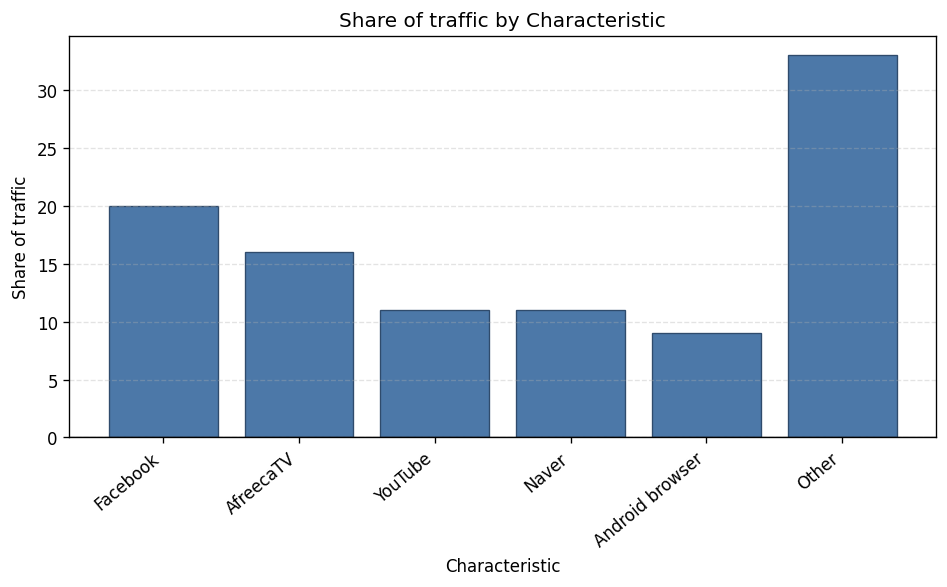


 hard_negative | v_bar | data: chartqa_train_two_col_20843__shuffled


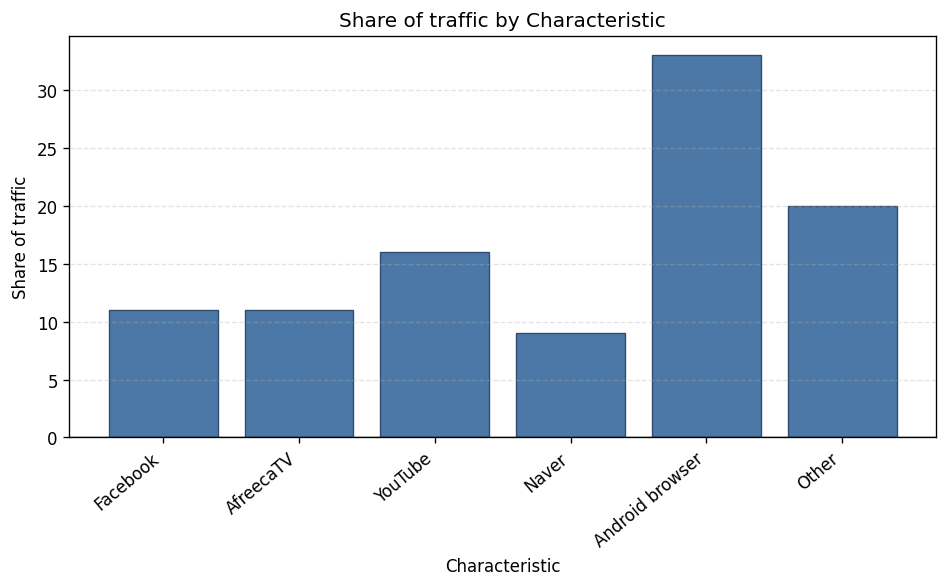

In [102]:
from IPython.display import display
from PIL import Image

sample_data_id = generated_charts_df.iloc[0][
    "source_data_id"
]

sample_charts = generated_charts_df[
    generated_charts_df["source_data_id"]
    == sample_data_id
].sort_values(
    ["chart_type", "variant_type"]
)

for _, chart in sample_charts.iterrows():
    print(
        "\n",
        chart["variant_type"],
        "|",
        chart["chart_type"],
        "| data:",
        chart["data_id"]
    )

    display(Image.open(chart["image_path"]))

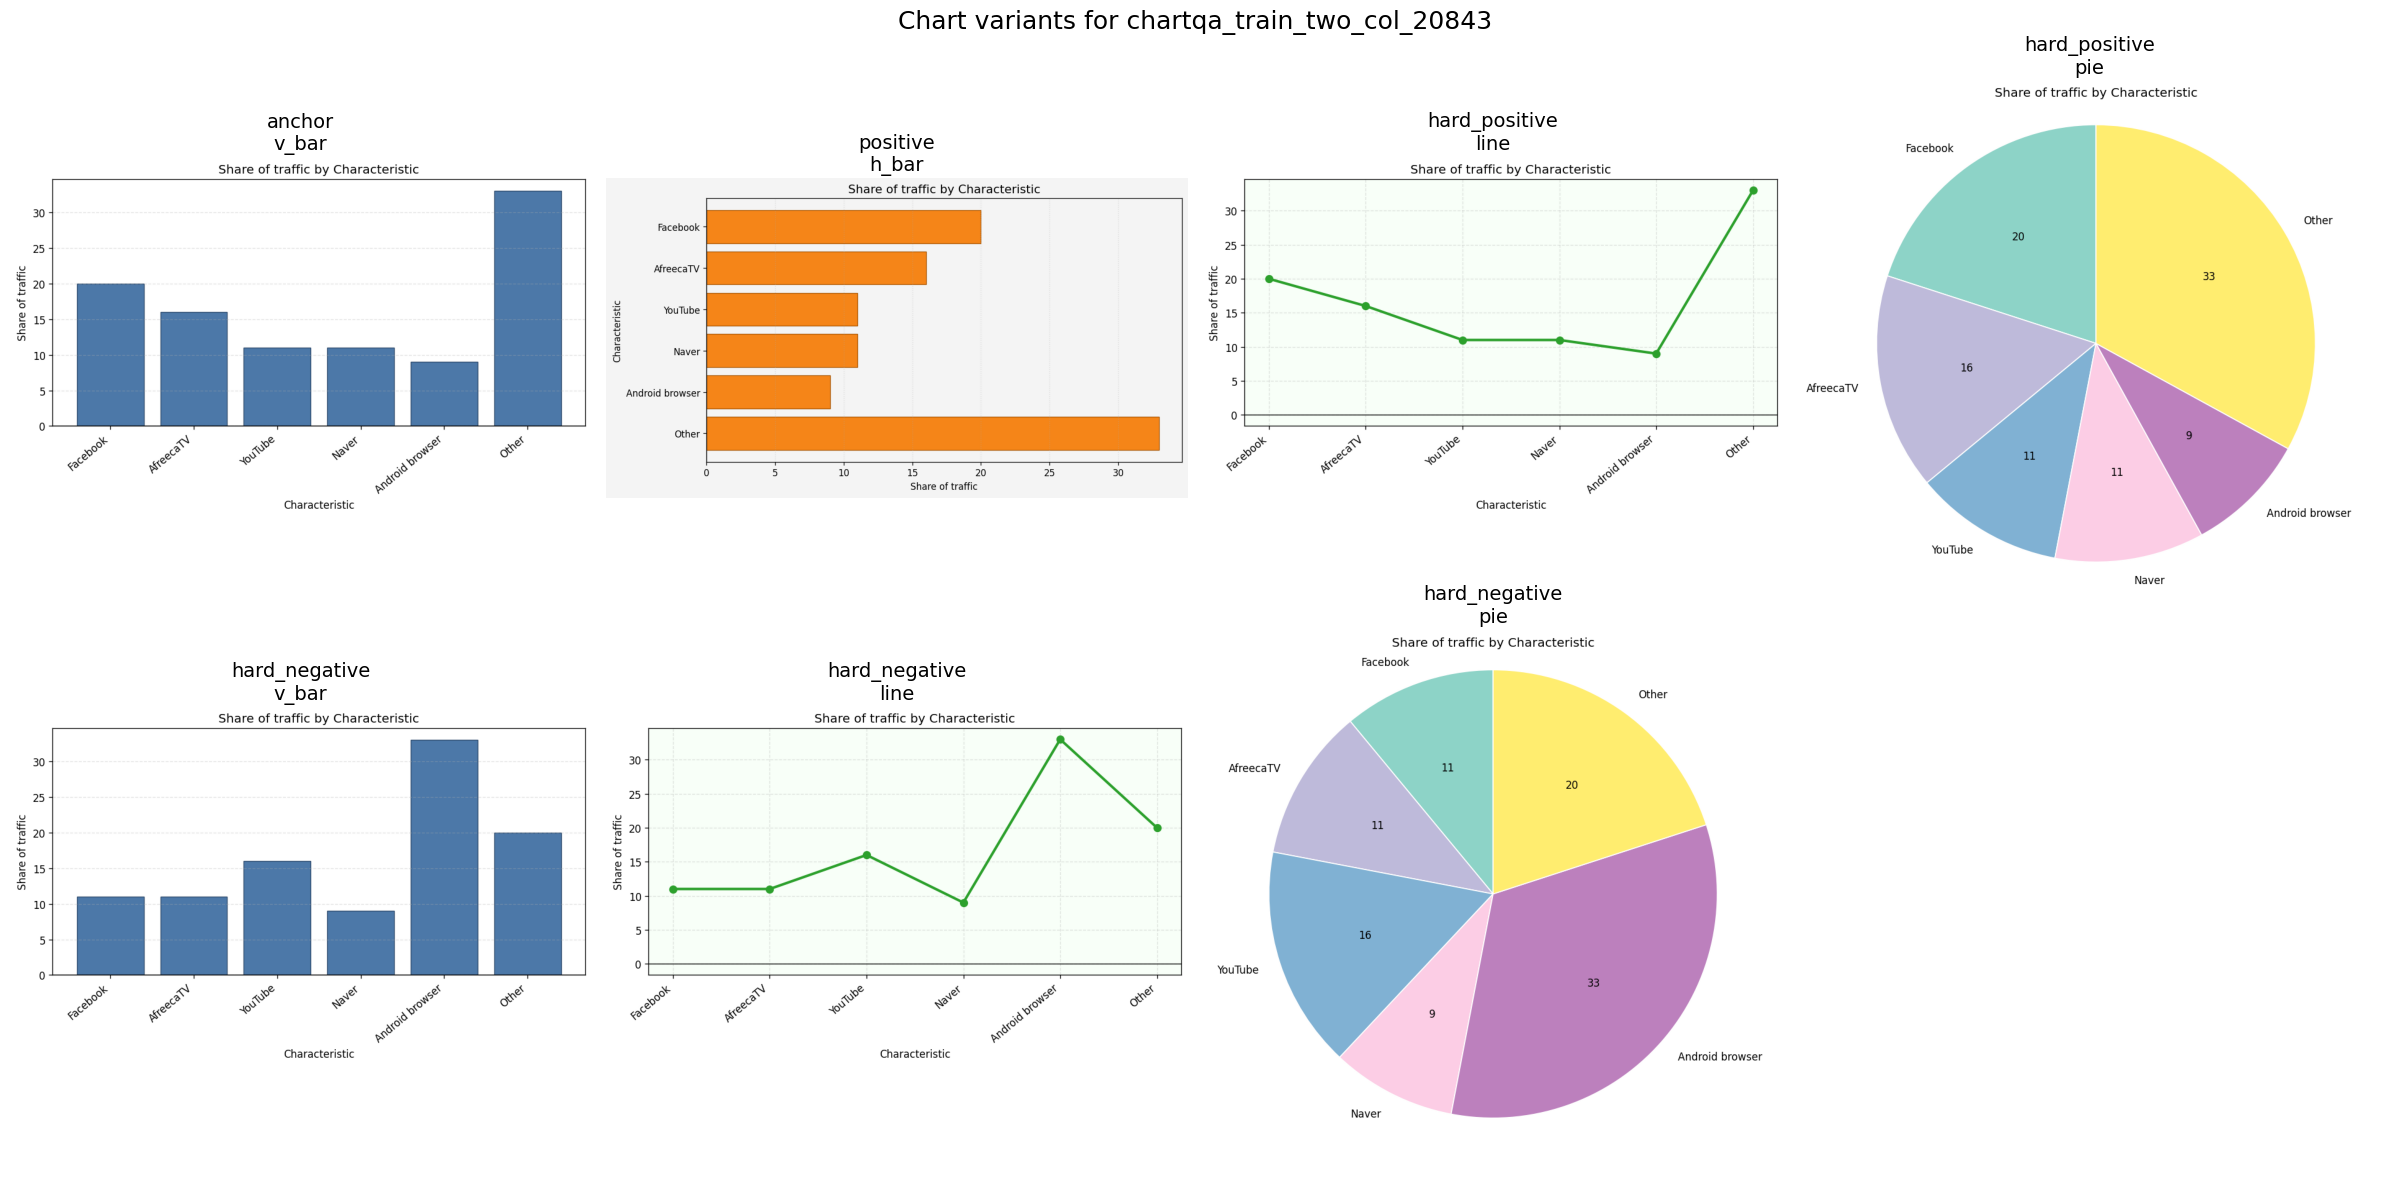

In [103]:
%matplotlib inline

import math
import matplotlib.pyplot as plt
from PIL import Image

sample_data_id = generated_charts_df.iloc[0]["source_data_id"]

sample_charts = generated_charts_df[
    generated_charts_df["source_data_id"] == sample_data_id
].copy()

display_order = {
    ("v_bar", "anchor"): 0,
    ("h_bar", "positive"): 1,
    ("line", "hard_positive"): 2,
    ("pie", "hard_positive"): 3,
    ("v_bar", "hard_negative"): 4,
    ("line", "hard_negative"): 5,
    ("pie", "hard_negative"): 6
}

sample_charts["order"] = sample_charts.apply(
    lambda row: display_order.get(
        (row["chart_type"], row["variant_type"]),
        99
    ),
    axis=1
)

sample_charts = sample_charts.sort_values("order")

number_of_charts = len(sample_charts)
number_of_columns = 4
number_of_rows = math.ceil(
    number_of_charts / number_of_columns
)

fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(24, 6 * number_of_rows)
)

axes = axes.flatten()

for axis, (_, chart) in zip(
    axes,
    sample_charts.iterrows()
):
    image = Image.open(chart["image_path"])

    axis.imshow(image)

    axis.set_title(
        f"{chart['variant_type']}\n"
        f"{chart['chart_type']}",
        fontsize=14
    )

    axis.axis("off")

# Hide unused positions
for axis in axes[number_of_charts:]:
    axis.axis("off")

plt.suptitle(
    f"Chart variants for {sample_data_id}",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [104]:
PILOT_PATH = BENCHMARK_DIR / "pilot_tables.parquet"

print("Benchmark directory:", BENCHMARK_DIR)
print("Pilot file:", PILOT_PATH)
print("Pilot file exists:", PILOT_PATH.exists())

Benchmark directory: /home/pnola130/projects/chart_data_retrieval/data/benchmark
Pilot file: /home/pnola130/projects/chart_data_retrieval/data/benchmark/pilot_tables.parquet
Pilot file exists: True


In [105]:
from pathlib import Path
import sys
import pandas as pd
from src.generation.benchmark_generator import generate_benchmark
from src.generation.add_chart_type_variants import add_chart_type_variants

PROJECT_ROOT = Path("/home/pnola130/projects/chart_data_retrieval")

BENCHMARK_DIR = PROJECT_ROOT / "data" / "benchmark"
PILOT_PATH = BENCHMARK_DIR / "pilot_tables.parquet"
FULL_IMAGE_DIR = PROJECT_ROOT / "generated_charts" / "pilot"

assert PILOT_PATH.exists()

pilot_df = pd.read_parquet(PILOT_PATH)

print("Pilot tables:", len(pilot_df))
print(pilot_df["split"].value_counts())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))



Pilot tables: 700
split
train    500
val      100
test     100
Name: count, dtype: int64


In [106]:
generated_charts_df, benchmark_tables_df, pairs_df = (
    generate_benchmark(
        pilot_path=PILOT_PATH,
        output_directory=BENCHMARK_DIR,
        image_directory=FULL_IMAGE_DIR,
        limit_per_split=None,
        global_seed=42
    )
)

print("Base generation completed")
print("Charts:", len(generated_charts_df))
print("Tables:", len(benchmark_tables_df))
print("Pairs:", len(pairs_df))

Generating chart triplets:  57%|█████▋    | 402/700 [02:54<02:03,  2.41it/s]/home/pnola130/projects/chart_data_retrieval/src/generation/benchmark_generator.py:132: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()
/home/pnola130/projects/chart_data_retrieval/src/generation/benchmark_generator.py:132: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()
Generating chart triplets: 100%|██████████| 700/700 [05:02<00:00,  2.31it/s]

Base generation completed
Charts: 2100
Tables: 1400
Pairs: 2100


In [107]:
generated_charts_df, pairs_df = (
    add_chart_type_variants(
        pilot_path=PILOT_PATH,
        benchmark_directory=BENCHMARK_DIR,
        image_directory=FULL_IMAGE_DIR,
        limit_per_split=None,
        global_seed=42
    )
)

benchmark_tables_df = pd.read_parquet(
    BENCHMARK_DIR / "benchmark_tables.parquet"
)

print("All variants generated")
print("Charts:", len(generated_charts_df))
print("Tables:", len(benchmark_tables_df))
print("Pairs:", len(pairs_df))

Adding line and pie variants: 100%|██████████| 700/700 [04:30<00:00,  2.59it/s]

All variants generated
Charts: 4104
Tables: 1400
Pairs: 5106


In [108]:
pie_positive_count = len(
    generated_charts_df[
        (generated_charts_df["chart_type"] == "pie")
        & (
            generated_charts_df["is_hard_negative"]
            == False
        )
    ]
)

expected_charts = 3500 + (2 * pie_positive_count)
expected_tables = 1400
expected_pairs = 4200 + (3 * pie_positive_count)

print("Pie-eligible tables:", pie_positive_count)

print("\nExpected charts:", expected_charts)
print("Actual charts:", len(generated_charts_df))

print("\nExpected tables:", expected_tables)
print("Actual tables:", len(benchmark_tables_df))

print("\nExpected pairs:", expected_pairs)
print("Actual pairs:", len(pairs_df))

assert len(generated_charts_df) == expected_charts
assert len(benchmark_tables_df) == expected_tables
assert len(pairs_df) == expected_pairs

print("\nFull benchmark counts are correct")

Pie-eligible tables: 302

Expected charts: 4104
Actual charts: 4104

Expected tables: 1400
Actual tables: 1400

Expected pairs: 5106
Actual pairs: 5106

Full benchmark counts are correct


In [109]:
generated_charts_df["image_exists"] = (
    generated_charts_df["image_path"]
    .apply(lambda path: Path(path).exists())
)

generated_charts_df["image_size"] = (
    generated_charts_df["image_path"]
    .apply(
        lambda path: (
            Path(path).stat().st_size
            if Path(path).exists()
            else 0
        )
    )
)

print(
    generated_charts_df["image_exists"].value_counts()
)

assert generated_charts_df["image_exists"].all()
assert (generated_charts_df["image_size"] > 0).all()

print("All generated images are valid")

image_exists
True    4104
Name: count, dtype: int64
All generated images are valid


In [110]:
print("Charts by type:")
print(generated_charts_df["chart_type"].value_counts())

print("\nCharts by variant:")
print(generated_charts_df["variant_type"].value_counts())

print("\nCharts by split:")
print(generated_charts_df["split"].value_counts())

print("\nRetrieval pairs by task:")
print(pairs_df["task"].value_counts())

Charts by type:
chart_type
v_bar    1400
line     1400
h_bar     700
pie       604
Name: count, dtype: int64

Charts by variant:
variant_type
hard_negative    1702
hard_positive    1002
anchor            700
positive          700
Name: count, dtype: int64

Charts by split:
split
train    2918
test      594
val       592
Name: count, dtype: int64

Retrieval pairs by task:
task
chart_chart    2704
chart_table    2402
Name: count, dtype: int64


In [111]:
from pathlib import Path

PROJECT_ROOT = Path("/home/pnola130/projects/chart_data_retrieval")
BENCHMARK_DIR = PROJECT_ROOT / "data" / "benchmark"
FULL_IMAGE_DIR = PROJECT_ROOT / "generated_charts" / "pilot"

# Save the latest dataframes
generated_charts_df.to_parquet(
    BENCHMARK_DIR / "generated_charts.parquet",
    index=False
)

benchmark_tables_df.to_parquet(
    BENCHMARK_DIR / "benchmark_tables.parquet",
    index=False
)

pairs_df.to_parquet(
    BENCHMARK_DIR / "retrieval_pairs.parquet",
    index=False
)

# Validate
print("Charts saved:", len(generated_charts_df))
print("Tables saved:", len(benchmark_tables_df))
print("Pairs saved:", len(pairs_df))
print("PNG images:", len(list(FULL_IMAGE_DIR.rglob("*.png"))))

assert len(generated_charts_df) == 4104
assert len(benchmark_tables_df) == 1400
assert len(pairs_df) == 5106

print("\nFull benchmark saved successfully!")

Charts saved: 4104
Tables saved: 1400
Pairs saved: 5106
PNG images: 4104

Full benchmark saved successfully!
